In [99]:

from belfast.target_utils import query_data, cal_obs_mag, cal_abs_mag, remove_extinction
from belfast.cluster_utils import summarize_cluster_age, plot_mass_age, plot_mass_age_rot90
# from tqdm import tqdm
from belfast.isochrone_utils import read_isochrones

import numpy as np
import pandas as pd

from belfast.paths import REPO_ROOT, RESULTS_DIR, DATA_DIR

import matplotlib.pyplot as plt
# from matplotlib.patches import Patch

import matplotlib.colors as mcolors

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [100]:
# Pleiades
df_post_pleiades = summarize_cluster_age(cluster = 'Pleiades',
                                         samples_glob = str(RESULTS_DIR / 'Pleiades_DIRECT_results'/ '*' / 'posterior*.npz'),
                                         df_targets = pd.read_csv(DATA_DIR / 'clusters' / 'Pleiades_finalized_targets.csv'),
                                         save_name= DATA_DIR / 'clusters' / 'Pleiades_posterior_DIRECT_summary.csv',
                                         print_flag = False,
                                         )

# Praesepe
df_post_praesepe = summarize_cluster_age(cluster = 'Praesepe',
                                         samples_glob = str(RESULTS_DIR / 'Praesepe_DIRECT_results' / '*' / 'posterior*.npz'),
                                         df_targets = pd.read_csv(DATA_DIR / 'clusters' / 'Praesepe_finalized_targets.csv'),
                                         save_name= DATA_DIR / 'clusters' / 'Praesepe_posterior_DIRECT_summary.csv',
                                         print_flag = False,
                                         )

# Hyades
df_post_hyades = summarize_cluster_age(cluster = 'Hyades',
                                       samples_glob = str(RESULTS_DIR / 'Hyades_DIRECT_results' / '*' / 'posterior*.npz'),
                                       df_targets = pd.read_csv(DATA_DIR / 'clusters' / 'Hyades_finalized_targets.csv'),
                                       save_name= DATA_DIR / 'clusters' / 'Hyades_posterior_DIRECT_summary.csv',
                                       print_flag = False,
                                       )

Reading lines: 100%|█████████▉| 312/313 [00:00<00:00, 17243.00it/s]


The number of isochrones: 1


Reading lines: 100%|█████████▉| 428/429 [00:00<00:00, 18350.37it/s]


The number of isochrones: 1


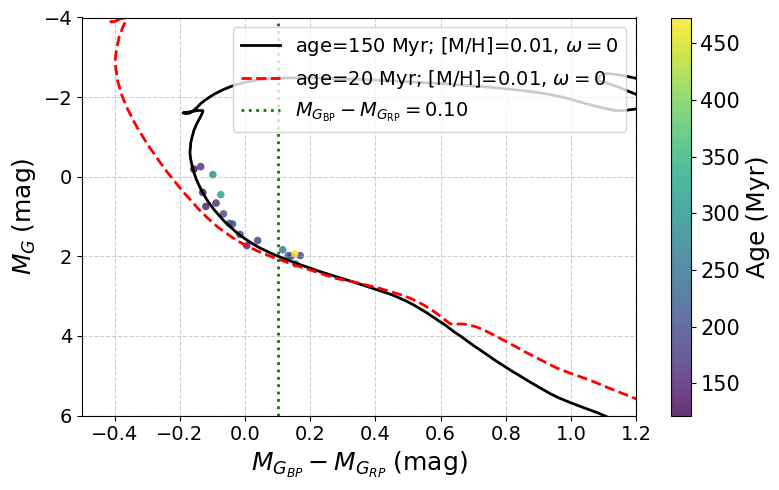

In [67]:
METHOD = "DIRECT"
# METHOD = "PARS"

cluster = "Pleiades"

df_post_pleiades = pd.read_csv(DATA_DIR / "clusters" / f"Pleiades_posterior_{METHOD}_summary.csv")
# df_post_pleiades = pd.read_csv('../data/clusters/pleiades_posterior_non_rot_DIRECT_summary.csv')

# df_post = df_post_pleiades.copy()

iso_pleiades = read_isochrones(DATA_DIR / "clusters" / "reference isochrones" / "Pleiades_age_150Myr_MH_+0.01_omega_ini_0.dat")

iso_beta_pic = read_isochrones(DATA_DIR / "clusters" / "reference isochrones" / "20Myr_MH_+0.01_omega_ini_0.dat")

Pleiades_G = iso_pleiades[0]["G_i00"].values
Pleiades_G_BP = iso_pleiades[0]["G_BP_i00"].values
Pleiades_G_RP = iso_pleiades[0]["G_RP_i00"].values

Beta_Pic_G = iso_beta_pic[0]["G_i00"].values
Beta_Pic_G_BP = iso_beta_pic[0]["G_BP_i00"].values
Beta_Pic_G_RP = iso_beta_pic[0]["G_RP_i00"].values

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    Pleiades_G_BP - Pleiades_G_RP,
    Pleiades_G,
    label=r"age=150 Myr; [M/H]=0.01, $\omega=0$",
    c="black",
    linewidth=2,
)

ax.plot(
    Beta_Pic_G_BP - Beta_Pic_G_RP,
    Beta_Pic_G,
    linestyle="--",
    label=r"age=20 Myr; [M/H]=0.01, $\omega=0$",
    c="red",
    linewidth=2,
)

c = df_post_pleiades["age"]
color_label = "Age (Myr)"

# special_hd_ids = [23862.0, 23432.0, 23629.0]
special_hd_ids = []

norm = mcolors.Normalize(vmin=c.min(), vmax=c.max())
cmap = plt.cm.viridis

mask_special = df_post_pleiades["HD_ID"].isin(special_hd_ids)
mask_normal = ~mask_special

sc = ax.scatter(
    df_post_pleiades.loc[mask_normal, "MBP_MRP"],
    df_post_pleiades.loc[mask_normal, "MG"],
    c=df_post_pleiades.loc[mask_normal, "age"],
    cmap=cmap,
    norm=norm,
    s=30,
    alpha=0.8,
    marker="o",
    edgecolors="none",
)

ax.scatter(
    df_post_pleiades.loc[mask_special, "MBP_MRP"],
    df_post_pleiades.loc[mask_special, "MG"],
    c=df_post_pleiades.loc[mask_special, "age"],
    cmap=cmap,
    norm=norm,
    s=45,
    alpha=1.0,
    marker="^",
    edgecolors="none",
)

# problem_stars = df_post_pleiades[
#     (df_post_pleiades["MBP_MRP"] < 0.18) &
#     (df_post_pleiades["age"] > 250)
# ].copy()
#
# if len(problem_stars) > 0:
#     x_text = problem_stars["MBP_MRP"].max() + 0.25
#
#     for _, row in problem_stars.iterrows():
#         x_star = row["MBP_MRP"]
#         y_star = row["MG"]
#
#         if not np.isnan(row["HIP_ID"]):
#             star_name = f"HIP {int(row['HIP_ID'])}"
#         else:
#             star_name = f"HD {int(row['HD_ID'])}"
#
#         ax.annotate(
#             star_name,
#             xy=(x_star + 0.03, y_star),
#             xytext=(x_text, y_star),
#             fontsize=14,
#             ha="left",
#             va="center",
#             arrowprops=dict(
#                 arrowstyle="->",
#                 linewidth=2.0,
#                 color="black",
#                 mutation_scale=18,
#                 shrinkA=0,
#                 shrinkB=0,
#             ),
#             bbox=dict(
#                 facecolor="white",
#                 alpha=0.8,
#                 edgecolor="none",
#                 pad=0.3,
#             ),
#             zorder=20,
#         )

x_line_pleiades = 0.1
# x_line_pleiades = 0.22

ax.axvline(
    x=x_line_pleiades,
    linestyle=":",
    color="green",
    linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}} - M_{{G_{{\mathrm{{RP}}}}}} = {x_line_pleiades:.2f}$",
)

ax.set_xlim([-0.5, 1.2])
ax.set_ylim([-4, 6])
ax.invert_yaxis()

ax.grid(True, linestyle="--", alpha=0.6)

ax.set_xlabel(
    r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.set_ylabel(
    r"$M_{\mathit{G}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.tick_params(axis="both", labelsize=14)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(color_label, fontsize=18)
cbar.ax.tick_params(labelsize=15)

ax.legend(loc="upper right", fontsize=14)

plt.tight_layout()

plt.savefig(
    DATA_DIR / "clusters" / "figures" / f"The Gaia color-magnitude diagram of the {cluster}.pdf"
)

plt.show()

In [88]:
df_post_pleiades[df_post_pleiades['MBP_MRP']>0.1][['HIP_ID', 'HD_ID', 'Spectral_Type', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age',
       'age_upper_uncertainty', 'age_lower_uncertainty', 'MBP_MRP']]

,HIP_ID,HD_ID,Spectral_Type,mass,mass_upper_uncertainty,mass_lower_uncertainty,age,age_upper_uncertainty,age_lower_uncertainty,MBP_MRP
2,17403.0,23155.0,A2,1.869207,0.029941,0.035997,199.68324,95.654400,64.139600,0.132946
4,NaN,23402.0,A0,1.901259,0.025999,0.030425,183.54616,79.628586,56.524933,0.169364
9,NaN,23643.0,A3Van,1.875403,0.029877,0.035027,194.55140,90.932510,61.717697,0.142255
11,NaN,23852.0,A0,1.821261,0.043602,0.043145,472.66547,125.905090,125.935640,0.152432
14,NaN,23886.0,A5Vn,1.739456,0.030846,0.036970,258.31830,136.944270,92.640580,0.155593
18,NaN,24178.0,A0,1.928287,0.040635,0.041933,260.55548,100.836610,92.458540,0.115685


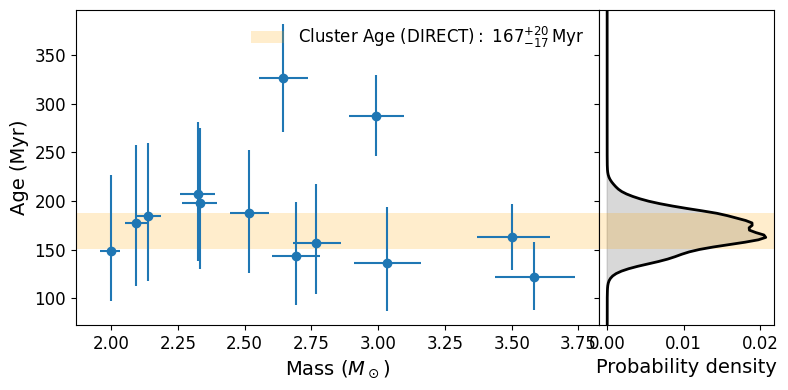

In [91]:
# df_post_pleiades_cut = df_post[(df_post['MBP_MRP']<x_line_pleiades)]
# df_post_pleiades_cut = df_tmp_pleiades[(df_tmp_pleiades['MBP_MRP']<x_line_pleiades) & (df_tmp_pleiades['sigma']<0.04)]
# df_post_pleiades_cut = df_tmp_pleiades[(df_tmp_pleiades['MBP_MRP']<x_line_pleiades) & (df_tmp_pleiades['sigma']<0.04) & (df_tmp_pleiades['age']<220)]


df_post_pleiades_cut = df_post_pleiades[
    (df_post_pleiades['MBP_MRP'] < 0.10)
    # (df_post_pleiades['HIP_ID'] != 17851) # large sigma
    # & (df_post_pleiades['HIP_ID'] != 17579) # old
    # & (df_post_pleiades['HD_ID']  != 23629) # old
    # & (df_post_pleiades['HIP_ID']  != 17588) # bianry?
]

# df_post_pleiades_cut = df_post_pleiades

plot_mass_age('Pleiades',
              df_post_pleiades_cut,
              weight='BANYAN_prob_PLE',
              method=METHOD,
              title= False,
              # legend_loc='upper right',
              save_name=DATA_DIR / "clusters" / "figures" / f"Mass-Age_relation_of_the_Pleiades_{METHOD} (MBP_MRP<0.10).pdf",
              )

# plot_mass_age_rot90('Pleiades',
#                     df_post_pleiades_cut,
#                     weight=False,
#                     method=METHOD,
#                     title= False,
#                     legend_loc='upper right',
#                     save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Pleiades_{METHOD}_rot90.pdf'
#                     )


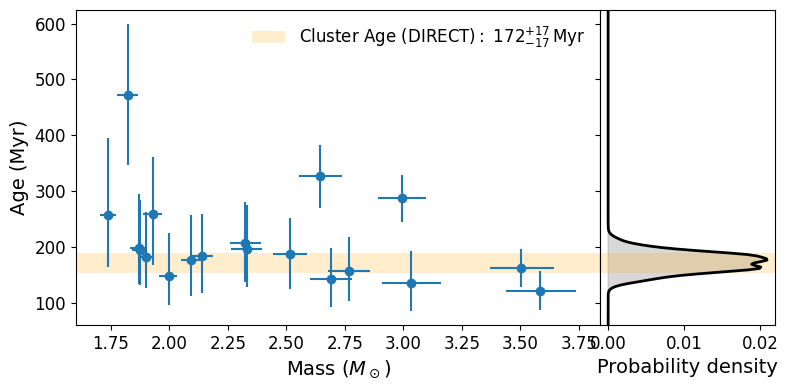

In [98]:
# df_post_pleiades_cut = df_post[(df_post['MBP_MRP']<x_line_pleiades)]
# df_post_pleiades_cut = df_tmp_pleiades[(df_tmp_pleiades['MBP_MRP']<x_line_pleiades) & (df_tmp_pleiades['sigma']<0.04)]
# df_post_pleiades_cut = df_tmp_pleiades[(df_tmp_pleiades['MBP_MRP']<x_line_pleiades) & (df_tmp_pleiades['sigma']<0.04) & (df_tmp_pleiades['age']<220)]


# df_post_pleiades_cut = df_post_pleiades[
#     (df_post_pleiades['MBP_MRP'] < 0.10)
#     # (df_post_pleiades['HIP_ID'] != 17851) # large sigma
#     # & (df_post_pleiades['HIP_ID'] != 17579) # old
#     # & (df_post_pleiades['HD_ID']  != 23629) # old
#     # & (df_post_pleiades['HIP_ID']  != 17588) # bianry?
# ]

df_post_pleiades_cut = df_post_pleiades

plot_mass_age('Pleiades',
              df_post_pleiades_cut,
              weight='BANYAN_prob_PLE',
              method=METHOD,
              title= False,
              # legend_loc='upper right',
              save_name=DATA_DIR / "clusters" / "figures" / f"Mass-Age_relation_of_the_Pleiades_{METHOD} (MBP_MRP<0.18).pdf",
              )

# plot_mass_age_rot90('Pleiades',
#                     df_post_pleiades_cut,
#                     weight=False,
#                     method=METHOD,
#                     title= False,
#                     legend_loc='upper right',
#                     save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Pleiades_{METHOD}_rot90.pdf'
#                     )


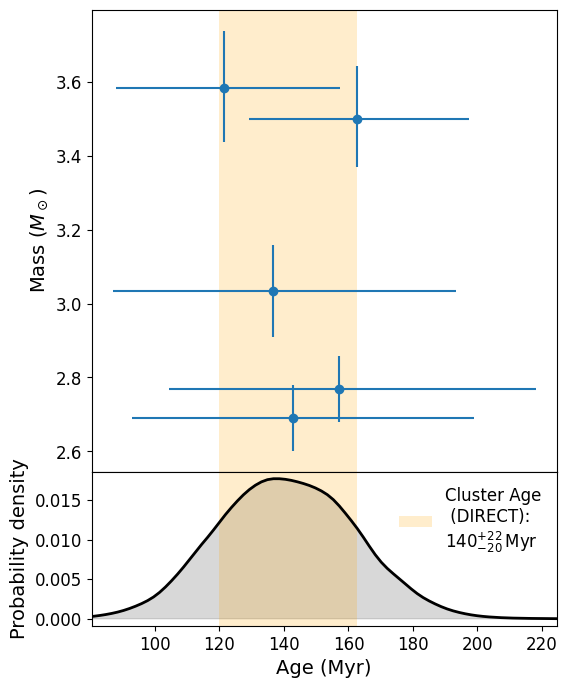

In [35]:
Pleiades_B_stars = [17527, 17588, 17776, 17862, 17900]
df_Pleiades_B_stars = df_post_pleiades[df_post_pleiades['HIP_ID'].isin(Pleiades_B_stars)]

plot_mass_age_rot90('Pleiades',
                    df_Pleiades_B_stars,
                    weight='BANYAN_prob_PLE',
                    method=METHOD,
                    title= False,
                    legend_loc='upper right',
                    save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Pleiades_B_stars_{METHOD}_rot90.pdf'
                    )

Reading lines: 100%|█████████▉| 544/545 [00:00<00:00, 19400.90it/s]


The number of isochrones: 1


Reading lines: 100%|█████████▉| 426/427 [00:00<00:00, 20589.69it/s]


The number of isochrones: 1
HIP 42523 not found.


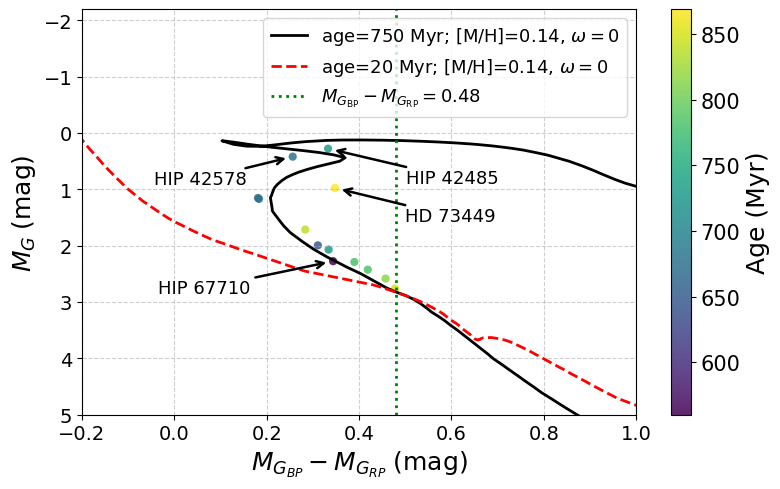

In [36]:
METHOD = "DIRECT"
# METHOD = "PARS"

cluster = "Praesepe"

df_post_praesepe = pd.read_csv(DATA_DIR / 'clusters' / f'praesepe_posterior_{METHOD}_summary.csv'
)

# df_post_praesepe = pd.read_csv('../data/clusters/praesepe_posterior_non_rot_DIRECT_summary.csv')

# df_post = df_post_praesepe.copy()

iso_praesepe = read_isochrones(DATA_DIR / 'clusters' / 'reference isochrones' / 'Praesepe_age_750Myr_MH_+0.14_omega_ini_0.dat')

iso_beta_pic = read_isochrones(DATA_DIR / 'clusters' / 'reference isochrones' / '20Myr_MH_+0.14_omega_ini_0.dat')

Praesepe_G = iso_praesepe[0]["G_i00"].values
Praesepe_G_BP = iso_praesepe[0]["G_BP_i00"].values
Praesepe_G_RP = iso_praesepe[0]["G_RP_i00"].values

Beta_Pic_G = iso_beta_pic[0]["G_i00"].values
Beta_Pic_G_BP = iso_beta_pic[0]["G_BP_i00"].values
Beta_Pic_G_RP = iso_beta_pic[0]["G_RP_i00"].values


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    Praesepe_G_BP - Praesepe_G_RP,
    Praesepe_G,
    label=r"age=750 Myr; [M/H]=0.14, $\omega=0$",
    c="black",
    linewidth=2,
)

ax.plot(
    Beta_Pic_G_BP - Beta_Pic_G_RP,
    Beta_Pic_G,
    linestyle="--",
    label=r"age=20 Myr; [M/H]=0.14, $\omega=0$",
    c="red",
    linewidth=2,
)

c = df_post_praesepe["age"]
color_label = "Age (Myr)"

sc = ax.scatter(
    df_post_praesepe['MBP_MRP'],
    df_post_praesepe['MG'],
    c=c,
    cmap="viridis",
    s=35,
    alpha=0.85,
    edgecolors="none",
)

x_line_praesepe = 0.48

ax.axvline(
    x=x_line_praesepe,
    linestyle=":",
    color="green",
    linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}} - M_{{G_{{\mathrm{{RP}}}}}} = {x_line_praesepe:.2f}$",
)

# ============================================================
# Annotate selected stars
# 42578: 8 o'clock
# 42523: 12 o'clock
# 42485: 4 o'clock
# HD 73449: 4 o'clock
# Note: y-axis is inverted later, so positive dy appears downward.
# ============================================================
targets = [
    {"id_col": "HIP_ID", "id": 42578, "label": "HIP 42578", "offset": (-0.2, 0.4)},
    {"id_col": "HD_ID", "id": 67710, "label": "HIP 67710", "offset": (-0.28, 0.48)},
    {"id_col": "HIP_ID", "id": 42523, "label": "HIP 42523", "offset": (0.00, -1.00)},
    {"id_col": "HIP_ID", "id": 42485, "label": "HIP 42485", "offset": (0.27, 0.52)},
    {"id_col": "HD_ID",  "id": 73449, "label": "HD 73449",  "offset": (0.25, 0.50)},
]

for target_i in targets:
    id_col = target_i["id_col"]
    star_id = target_i["id"]
    label = target_i["label"]
    dx, dy = target_i["offset"]

    df_star = df_post_praesepe[df_post_praesepe[id_col] == star_id]

    if len(df_star) == 0:
        print(f"{label} not found.")
        continue

    x_star = df_star["MBP_MRP"].values[0]
    y_star = df_star["MG"].values[0]

    ax.annotate(
        label,
        xy=(x_star, y_star),
        xytext=(x_star + dx, y_star + dy),
        fontsize=13,
        color="black",
        ha="center",
        va="center",
        arrowprops=dict(
            arrowstyle="->",
            lw=1.8,
            color="black",
            shrinkA=5,
            shrinkB=5,
        ),
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none",
            pad=0.3,
        ),
        zorder=20,
    )

ax.set_xlim([-0.2, 1.0])
ax.set_ylim([-2.2, 5])
ax.invert_yaxis()

ax.grid(True, linestyle="--", alpha=0.6)

ax.set_xlabel(
    r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.set_ylabel(
    r"$M_{\mathit{G}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.tick_params(axis="both", labelsize=14)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(color_label, fontsize=18)
cbar.ax.tick_params(labelsize=15)

ax.legend(fontsize=13)

plt.tight_layout()

plt.savefig(DATA_DIR / 'clusters' / 'figures' / f'The Gaia color-magnitude diagram of the {cluster}.pdf')

plt.show()

In [96]:
df_post_praesepe[df_post_praesepe['MBP_MRP']>0.47][['HIP_ID', 'HD_ID', 'Other_Name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age',
        'age_upper_uncertainty', 'age_lower_uncertainty', ]]

,HIP_ID,HD_ID,Other_Name,mass,mass_upper_uncertainty,mass_lower_uncertainty,age,age_upper_uncertainty,age_lower_uncertainty
1,NaN,NaN,TIC 14455755,1.51389,0.040225,0.041538,850.1617,275.3775,352.46884


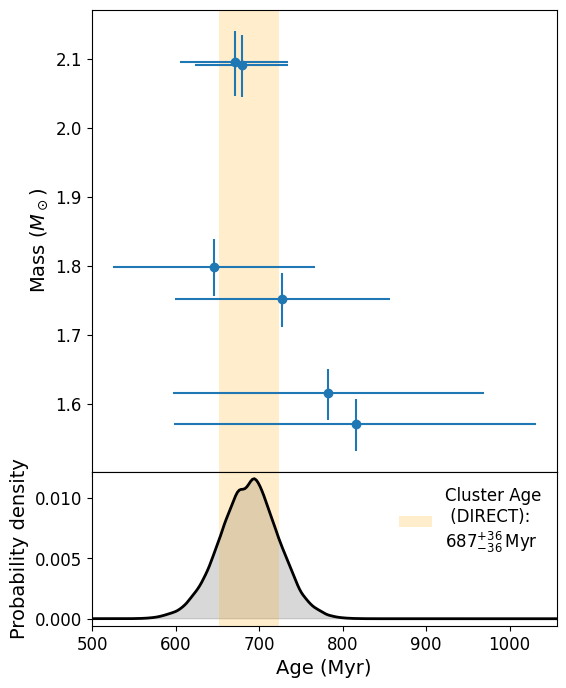

In [51]:
# df_post_praesepe_cut = df_tmp_praesepe[df_tmp_praesepe['MBP_MRP']<x_line_praesepe]
df_post_praesepe_cut = df_post_praesepe[
    # (df_post['MBP_MRP'] < x_line_praesepe)
    # (df_post['HIP_ID'] != 42523) # blue straggler
    (df_post_praesepe['HD_ID'] != 67710) # unsure membership
    & (df_post_praesepe['HD_ID'] != 73818) # chemically peculiar stars
    & (df_post_praesepe['HD_ID'] != 73449) # no visni
    & (df_post_praesepe['HIP_ID'] != 42578) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42485) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42993) # Am star
    & (df_post_praesepe['Other_Name'] != 'TIC 14455755')
]

# plot_mass_age('Praesepe',
#               df_post_praesepe_cut,
#               weight=False,
#               method=METHOD,
#               title= False,
#               # legend_loc='upper right',
#               save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Praesepe_{METHOD} (no Am stars).pdf'
#               )

plot_mass_age_rot90('Praesepe',
                    df_post_praesepe_cut,
                    weight=False,
                    method=METHOD,
                    title= False,
                    legend_loc='upper right',
                    # save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Praesepe_{METHOD}_rot90 (no Am stars).pdf'
                    )


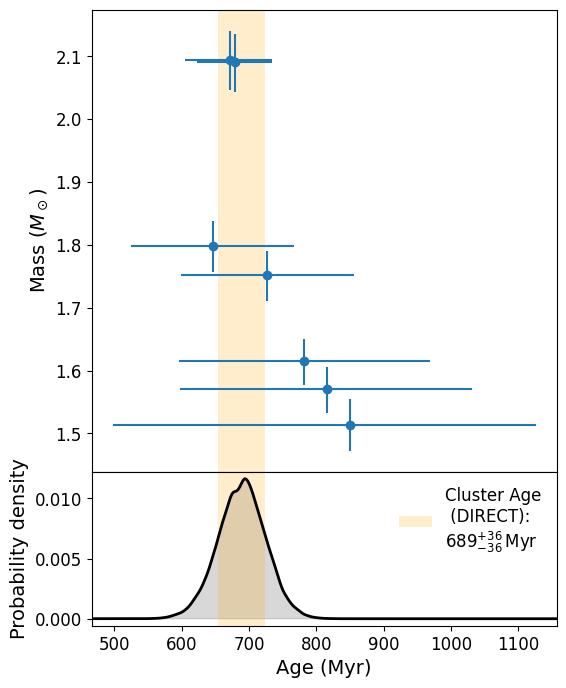

In [37]:
# df_post_praesepe_cut = df_tmp_praesepe[df_tmp_praesepe['MBP_MRP']<x_line_praesepe]
df_post_praesepe_cut = df_post_praesepe[
    # (df_post['MBP_MRP'] < x_line_praesepe)
    # (df_post['HIP_ID'] != 42523) # blue straggler
    (df_post_praesepe['HD_ID'] != 67710) # unsure membership
    & (df_post_praesepe['HD_ID'] != 73818) # chemically peculiar stars
    & (df_post_praesepe['HD_ID'] != 73449) # no visni
    & (df_post_praesepe['HIP_ID'] != 42578) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42485) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42993) # Am star
]

# plot_mass_age('Praesepe',
#               df_post_praesepe_cut,
#               weight=False,
#               method=METHOD,
#               title= False,
#               # legend_loc='upper right',
#               save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Praesepe_{METHOD} (no Am stars).pdf'
#               )

plot_mass_age_rot90('Praesepe',
                    df_post_praesepe_cut,
                    weight=False,
                    method=METHOD,
                    title= False,
                    legend_loc='upper right',
                    save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Praesepe_{METHOD}_rot90 (no Am stars).pdf'
                    )


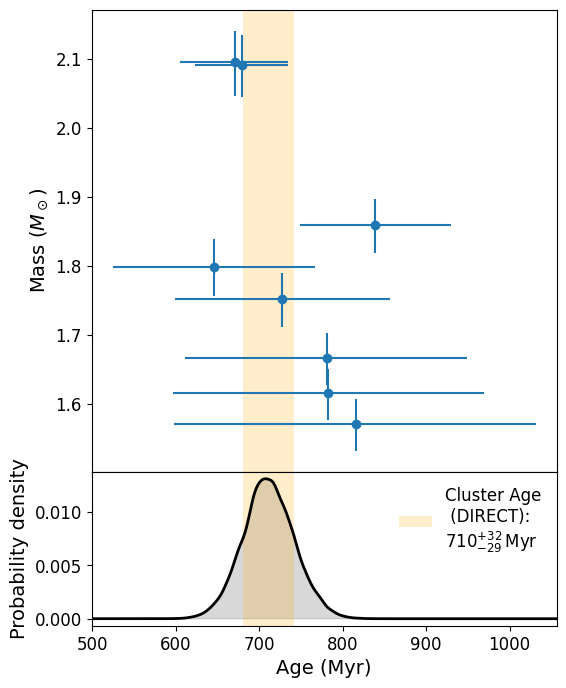

In [38]:

# df_post_praesepe_cut = df_tmp_praesepe[df_tmp_praesepe['MBP_MRP']<x_line_praesepe]
df_post_praesepe_cut = df_post_praesepe[
    # (df_post['MBP_MRP'] < x_line_praesepe)
    # (df_post['HIP_ID'] != 42523) # blue straggler
    (df_post_praesepe['HD_ID'] != 67710) # unsure membership
    # & (df_post_praesepe['HD_ID'] != 73818) # chemically peculiar stars
    & (df_post_praesepe['HD_ID'] != 73449) # no visni
    & (df_post_praesepe['Other_Name'] != 'TIC 14455755') # no visni
    & (df_post_praesepe['HIP_ID'] != 42578) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42485) # SGB?
    # & (df_post_praesepe['HIP_ID'] != 42993) # Am star
]

# plot_mass_age('Praesepe',
#               df_post_praesepe_cut,
#               weight=False,
#               method=METHOD,
#               title= False,
#               # legend_loc='upper right',
#               save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Praesepe_{METHOD} (no Am stars).pdf'
#               )

plot_mass_age_rot90('Praesepe',
                    df_post_praesepe_cut,
                    weight=False,
                    method=METHOD,
                    title= False,
                    legend_loc='upper right',
                    save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Praesepe_{METHOD}_rot90 (with Am stars).pdf'
                    )


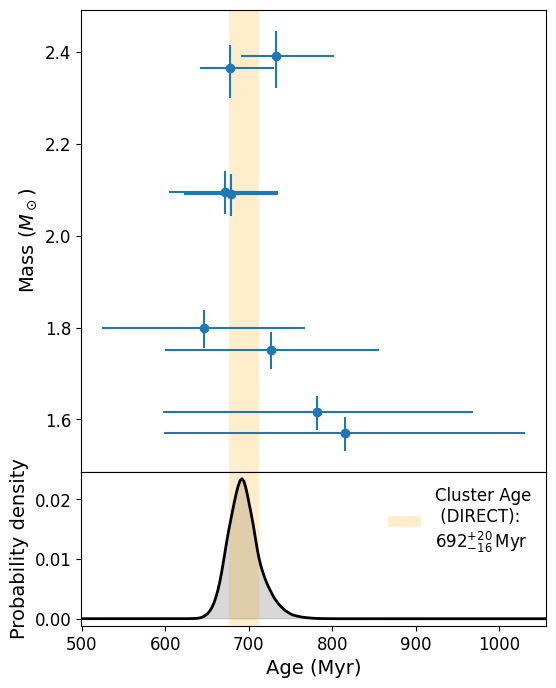

In [39]:
# df_post_praesepe_cut = df_tmp_praesepe[df_tmp_praesepe['MBP_MRP']<x_line_praesepe]
df_post_praesepe_cut = df_post_praesepe[
    # (df_post['MBP_MRP'] < x_line_praesepe)
    # (df_post['HIP_ID'] != 42523) # blue starggler
    (df_post_praesepe['HD_ID']  != 73449) # no visni
    & (df_post_praesepe['Other_Name'] != 'TIC 14455755') # no visni
    & (df_post_praesepe['HD_ID']  != 67710) # unsure membership
    & (df_post_praesepe['HD_ID']  != 73818) # chemically peculiar stars
    # & (df_post['HIP_ID'] != 42578) # SGB?
    # & (df_post['HIP_ID'] != 42485) # SGB?
    & (df_post_praesepe['HIP_ID'] != 42993) # Am star
]

# plot_mass_age('Praesepe',
#               df_post_praesepe_cut,
#               weight=False,
#               method=METHOD,
#               title= False,
#               save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Praesepe_{METHOD} (with possible SGB stars but no Am stars).pdf',
#               # age_xlim=[250, 950]
#               )

plot_mass_age_rot90('Praesepe',
                    df_post_praesepe_cut,
                    weight=False,
                    method=METHOD,
                    title= False,
                    save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Praesepe_{METHOD} (with possible SGB stars but no Am stars)_rot90.pdf',
                    # age_xlim=[250, 950]
                    legend_loc='upper right',
                    )

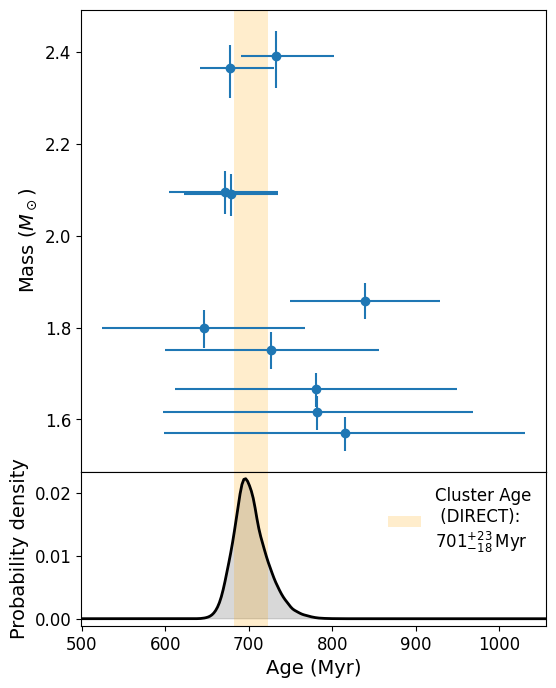

In [40]:
# df_post_praesepe_cut = df_tmp_praesepe[df_tmp_praesepe['MBP_MRP']<x_line_praesepe]
df_post_praesepe_cut = df_post_praesepe[
    # (df_post['MBP_MRP'] < x_line_praesepe)
    # (df_post['HIP_ID'] != 42523) # blue starggler
    (df_post_praesepe['HD_ID']  != 73449) # no visni
    & (df_post_praesepe['Other_Name'] != 'TIC 14455755') # no visni
    & (df_post_praesepe['HD_ID']  != 67710) # unsure membership
    # & (df_post_praesepe['HD_ID']  != 73818) # chemically peculiar stars
    # & (df_post['HIP_ID'] != 42578) # SGB?
    # & (df_post['HIP_ID'] != 42485) # SGB?
    # & (df_post_praesepe['HIP_ID'] != 42993) # Am star
]

# plot_mass_age('Praesepe',
#               df_post_praesepe_cut,
#               weight=False,
#               method=METHOD,
#               title= False,
#               save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Praesepe_{METHOD} (with possible SGB stars but no Am stars).pdf',
#               # age_xlim=[250, 950]
#               )

plot_mass_age_rot90('Praesepe',
                    df_post_praesepe_cut,
                    weight=False,
                    method=METHOD,
                    title= False,
                    save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Praesepe_{METHOD} (with possible SGB stars and Am stars)_rot90.pdf',
                    # age_xlim=[250, 950]
                    legend_loc='upper right',
                    )

Reading lines: 100%|█████████▉| 535/536 [00:00<00:00, 20630.82it/s]


The number of isochrones: 1


Reading lines: 100%|█████████▉| 424/425 [00:00<00:00, 19917.40it/s]

The number of isochrones: 1


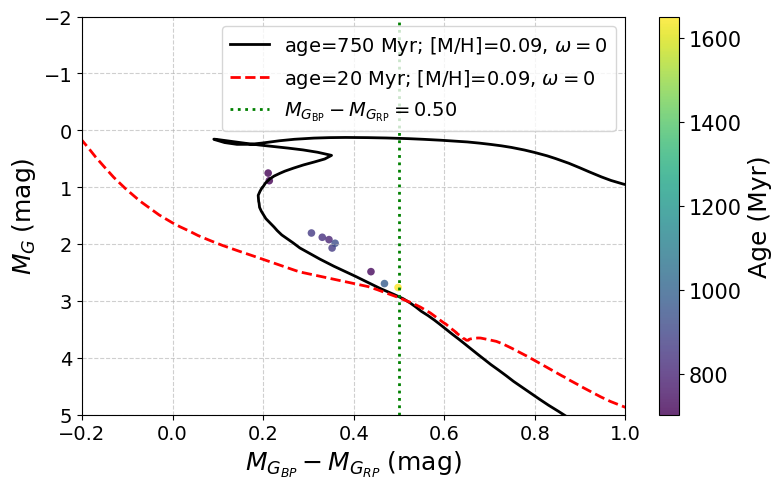

In [41]:
METHOD = "DIRECT"
# METHOD = "PARS"

cluster = "Hyades"

df_post_hyades = pd.read_csv(DATA_DIR / 'clusters' / f'hyades_posterior_{METHOD}_summary.csv')

# df_post_hyades = pd.read_csv(f"../data/clusters/hyades_posterior_non_rot_DIRECT_summary.csv")

# df_post = df_post_hyades.copy()

iso_hyades = read_isochrones(DATA_DIR / 'clusters' / 'reference isochrones' / 'Hyades_age_750Myr_MH_+0.09_omega_ini_0.dat')

iso_beta_pic = read_isochrones(DATA_DIR / 'clusters' / 'reference isochrones' / '20Myr_MH_+0.09_omega_ini_0.dat')

Hyades_G = iso_hyades[0]["G_i00"].values
Hyades_G_BP = iso_hyades[0]["G_BP_i00"].values
Hyades_G_RP = iso_hyades[0]["G_RP_i00"].values

Beta_Pic_G = iso_beta_pic[0]["G_i00"].values
Beta_Pic_G_BP = iso_beta_pic[0]["G_BP_i00"].values
Beta_Pic_G_RP = iso_beta_pic[0]["G_RP_i00"].values

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    Hyades_G_BP - Hyades_G_RP,
    Hyades_G,
    label=r"age=750 Myr; [M/H]=0.09, $\omega=0$",
    c="black",
    linewidth=2,
)

ax.plot(
    Beta_Pic_G_BP - Beta_Pic_G_RP,
    Beta_Pic_G,
    linestyle="--",
    label=r"age=20 Myr; [M/H]=0.09, $\omega=0$",
    c="red",
    linewidth=2,
)

c = df_post_hyades["age"]
color_label = "Age (Myr)"

sc = ax.scatter(
    df_post_hyades["MBP_MRP"],
    df_post_hyades["MG"],
    c=c,
    cmap="viridis",
    s=30,
    alpha=0.8,
    edgecolors="none",
)

x_line_hyades = 0.50

ax.axvline(
    x=x_line_hyades,
    linestyle=":",
    color="green",
    linewidth=2,
    label=rf"$M_{{G_{{\mathrm{{BP}}}}}} - M_{{G_{{\mathrm{{RP}}}}}} = {x_line_hyades:.2f}$",
)

ax.set_xlim([-0.2, 1.0])
ax.set_ylim([-2.0, 5.0])
ax.invert_yaxis()

ax.grid(True, linestyle="--", alpha=0.6)

ax.set_xlabel(
    r"$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.set_ylabel(
    r"$M_{\mathit{G}} \;(\mathrm{mag})$",
    fontsize=18,
)

ax.tick_params(axis="both", labelsize=14)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(color_label, fontsize=18)
cbar.ax.tick_params(labelsize=15)

ax.legend(fontsize=14)

plt.tight_layout()

plt.savefig(DATA_DIR / 'clusters' / 'figures'/ f'The Gaia color-magnitude diagram of the {cluster}.pdf')

plt.show()

In [80]:
df_post_hyades[df_post_hyades['MBP_MRP']<0.49][['HIP_ID', 'HD_ID', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age',
       'age_upper_uncertainty', 'age_lower_uncertainty',  ]]

,HIP_ID,HD_ID,mass,mass_upper_uncertainty,mass_lower_uncertainty,age,age_upper_uncertainty,age_lower_uncertainty
0,18170.0,24357.0,1.510247,0.030382,0.030461,979.62160,185.637450,214.623540
2,18735.0,25202.0,1.599647,0.035321,0.034459,722.16410,201.699040,240.301420
3,20641.0,27946.0,1.811344,0.040646,0.041179,796.34125,110.079346,107.395020
4,20635.0,27934.0,2.211832,0.047184,0.051069,702.35650,40.718080,40.729980
5,21670.0,29499.0,1.784956,0.036158,0.035935,834.99390,101.946840,107.815550
6,22044.0,30034.0,1.717626,0.036093,0.037726,868.68884,126.124695,129.922000
7,21036.0,28556.0,1.734056,0.034000,0.034096,922.66090,100.653440,106.457340
8,20261.0,27459.0,1.796321,0.035936,0.035305,862.95557,89.815674,96.992676
9,23497.0,32301.0,2.180189,0.039849,0.041001,704.84247,34.779785,35.039917


In [77]:
df_post_hyades.columns[-12:]

Index(['mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age',
       'age_upper_uncertainty', 'age_lower_uncertainty', 'u',
       'u_upper_uncertainty', 'u_lower_uncertainty', 'sigma',
       'sigma_upper_uncertainty', 'sigma_lower_uncertainty'],
      dtype='object')

TypeError: unsupported operand type(s) for +: 'bool' and 'str'

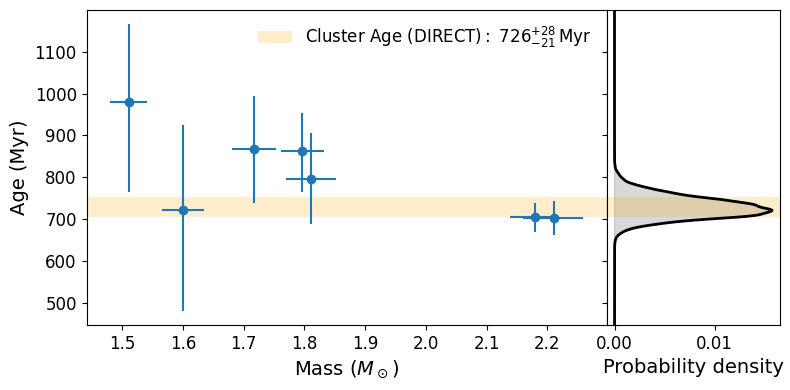

In [46]:
df_tmp_hyades_cut = df_post_hyades[
    # (df_post_hyades['MBP_MRP'] < x_line_hyades)
    (df_post_hyades['HIP_ID'] != 21036) # possible binary
    & (df_post_hyades['HIP_ID'] != 19261) # additional star
    & (df_post_hyades['HIP_ID'] != 21670) # Am star
]


plot_mass_age('Hyades',
              df_tmp_hyades_cut,
              weight='BANYAN_prob_HYA',
              method=METHOD,
              title=False,
              # legend_loc='upper right',
              # save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Hyades_{METHOD} (no Am stars).pdf',
              )

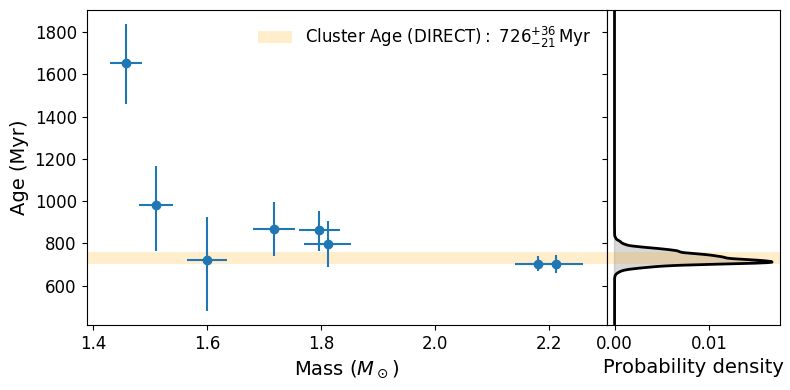

In [44]:
df_tmp_hyades_cut = df_post_hyades[
    # (df_post_hyades['MBP_MRP'] < x_line_hyades)
    (df_post_hyades['HIP_ID'] != 21036) # possible binary
    # & (df_post_hyades['HIP_ID'] != 19261) # additional star
    & (df_post_hyades['HIP_ID'] != 21670) # Am star
]


plot_mass_age('Hyades',
              df_tmp_hyades_cut,
              weight='BANYAN_prob_HYA',
              method=METHOD,
              title=False,
              # legend_loc='upper right',
              save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Hyades_{METHOD} (no Am stars).pdf',
              )

# plot_mass_age_rot90('Hyades',
#                     df_tmp_hyades_cut,
#                     weight=True,
#                     method=METHOD,
#                     title=False,
#                     legend_loc='upper right',
#                     save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Hyades_{METHOD}_rot90 (no Am stars).pdf',
#                     )


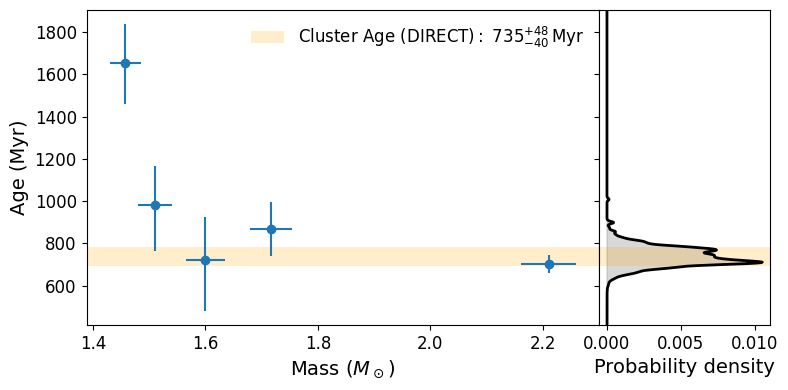

In [45]:
df_tmp_hyades_cut = df_post_hyades[
    # (df_post['MBP_MRP'] < x_line_hyades)
    (df_post_hyades['HIP_ID'] != 23497) # possible binary?
    & (df_post_hyades['HIP_ID'] != 20641) # $\delta$ Scuti variable
    & (df_post_hyades['HIP_ID'] != 21036) # possible binary?
    & (df_post_hyades['HIP_ID'] != 20261) # $\delta$ Scuti variable
    & (df_post_hyades['HIP_ID'] != 21670) # Am star
]

plot_mass_age('Hyades',
              df_tmp_hyades_cut,
              weight='BANYAN_prob_HYA',
              method=METHOD,
              title=False,
              save_name=DATA_DIR / 'clusters' / 'figures' / f'Mass-Age_relation_of_the_Hyades_no_bad_{METHOD}.pdf',
              )

# plot_mass_age_rot90('Hyades',
#                     df_tmp_hyades_cut,
#                     weight=True,
#                     method=METHOD,
#                     title=False,
#                     legend_loc='upper right',
#                     save_name=f'../data/clusters/figures/Mass-Age_relation_of_the_Hyades_no_bad_{METHOD}_rot90.pdf',
#                     )


In [ ]:
df_pleiades = pd.read_csv('../data/clusters/pleiades_targets.csv')
df_post_pleiades = pd.read_csv('../data/clusters/pleiades_posterior_summary.csv')

In [ ]:
df_praesepe = pd.read_csv('../data/clusters/praesepe_targets.csv')
df_post_praesepe = pd.read_csv('../data/clusters/praesepe_posterior_summary.csv')

In [ ]:
df_hyades = pd.read_csv('../data/clusters/hyades_targets.csv')
df_post_hyades = pd.read_csv('../data/clusters/hyades_posterior_summary.csv')

In [ ]:
# df_post_pleiades_cut = df_tmp_pleiades[df_tmp_pleiades['MBP_MRP']<x_line_pleiades]

In [ ]:
# df_post_praesepe_cut = df_tmp_praesepe[(df_tmp_praesepe['MBP_MRP']<x_line_praesepe)]

In [ ]:
# df_post_hyades_cut = df_tmp_hyades[(df_tmp_hyades['MBP_MRP']<x_line_hyades)]

In [ ]:
# df_post_pleiades_cut.to_csv('../data/clusters/df_post_pleiades_cut.csv', index=False)
# df_post_praesepe_cut.to_csv('../data/clusters/df_post_praesese_cut.csv', index=False)
# df_post_hyades_cut.to_csv('../data/clusters/df_post_hyades_cut.csv', index=False)

## compare the age of Pleiades using B-type stars

In [ ]:
cluster = 'Pleiades'
df_post_pleiades = pd.read_csv('../data/clusters/pleiades_posterior_summary.csv')

df_post = df_post_pleiades
iso_pleiades = read_isochrones('../data/clusters/reference isochrones/Pleiades_age_150Myr_MH_+0.01_omega_ini_0.dat')
iso_beta_pic = read_isochrones('../data/clusters/reference isochrones/20Myr_MH_+0.01_omega_ini_0.dat')

Pleiades_G = iso_pleiades[0]['G_i00'].values
Pleiades_G_BP = iso_pleiades[0]['G_BP_i00'].values
Pleiades_G_RP = iso_pleiades[0]['G_RP_i00'].values

Beta_Pic_G = iso_beta_pic[0]['G_i00'].values
Beta_Pic_G_BP = iso_beta_pic[0]['G_BP_i00'].values
Beta_Pic_G_RP = iso_beta_pic[0]['G_RP_i00'].values

plt.figure(figsize=(8,5))

plt.plot(Pleiades_G_BP - Pleiades_G_RP, Pleiades_G, label=r'age=150 Myr; [M/H]=0.01, $\omega=0$', c='black')
plt.plot(Beta_Pic_G_BP - Beta_Pic_G_RP, Beta_Pic_G, label=r'age=20 Myr; [M/H]=0.01, $\omega=0$', c='red')

y, _ = cal_abs_mag(df_post['G_mag'].values, df_post['G_err'].values, df_post['parallax'].values, df_post['parallax_err'].values)

x_obs1, _ = cal_abs_mag(df_post['G_BP_mag'].values, df_post['G_BP_err'].values, df_post['parallax'].values, df_post['parallax_err'].values)
x_obs2, _ = cal_abs_mag(df_post['G_RP_mag'].values, df_post['G_RP_err'].values, df_post['parallax'].values, df_post['parallax_err'].values)
x = x_obs1 - x_obs2

df_tmp_pleiades = df_post.copy()
df_tmp_pleiades['MBP_MRP'] = x



B_type_HIP_list = [17527, 17588, 17776, 17862, 17900]
df_B_type = df_post[df_post['HIP_ID'].isin(B_type_HIP_list)]

y_B_type, _ = cal_abs_mag(df_B_type['G_mag'].values, df_B_type['G_err'].values, df_B_type['parallax'].values, df_B_type['parallax_err'].values)

x_obs1_B_type, _ = cal_abs_mag(df_B_type['G_BP_mag'].values, df_B_type['G_BP_err'].values, df_B_type['parallax'].values, df_B_type['parallax_err'].values)
x_obs2_B_type, _ = cal_abs_mag(df_B_type['G_RP_mag'].values, df_B_type['G_RP_err'].values, df_B_type['parallax'].values, df_B_type['parallax_err'].values)
x_B_type = x_obs1_B_type - x_obs2_B_type

df_tmp_B_type = df_B_type.copy()
df_tmp_B_type['MBP_MRP'] = x_B_type




c = df_post['age']
color_label = 'Age (Myr)'

sc = plt.scatter(x, y, c=c, cmap="viridis",   # 也可以试试 'plasma', 'magma', 'inferno'
    s=30,
    alpha=0.8)

plt.scatter(x_B_type, y_B_type, marker='*', c='red', label='B-type stars',   # 也可以试试 'plasma', 'magma', 'inferno'
    s=30,
    alpha=0.8)

plt.xlim([-0.5, 1.5])
plt.ylim([-4, 6])

x_line = 0.18
plt.axvline(x=x_line, label=rf'$M_{{G_{{\mathrm{{BP}}}}}} - M_{{G_{{\mathrm{{RP}}}}}} = {x_line:.2f}$')

plt.gca().invert_yaxis()

plt.grid(True, linestyle='--', alpha=0.6)

plt.title(f'The Gaia color-magnitude diagram of the {cluster} (B-type stars)', fontsize=14)
plt.xlabel(r'$M_{G_\mathit{BP}} - M_{G_\mathit{RP}} \;(\mathrm{mag})$', fontsize=14)
plt.ylabel(r'$M_{\mathit{G}} \;(\mathrm{mag})$', fontsize=14)

cbar = plt.colorbar(sc)
cbar.set_label(color_label, fontsize=18)

plt.tight_layout()

plt.legend()
plt.savefig(f'../data/clusters/figures/The Gaia color-magnitude diagram of the {cluster} (B-type stars).pdf')
plt.show()

In [ ]:
# df_post_hyades_cut = df_tmp_hyades[(df_tmp_hyades['MBP_MRP']<x_line)]

plot_mass_age('Hyades',
              df_tmp_B_type,
              weight=True,
              method=METHOD,
              title='Mass-Age relation of the Pleiades (B-type stars).pdf'
              )


In [ ]:
df_post_pleiades_cut

In [ ]:
# compare new method results

In [ ]:
df_pleiades_old = pd.read_csv('../data/clusters/old/pleiades_posterior_summary.csv')
df_pleiades_new = pd.read_csv('../data/clusters/pleiades_posterior_summary.csv')

df_hyades_old = pd.read_csv('../data/clusters/old/hyades_posterior_summary.csv')
df_hyades_new = pd.read_csv('../data/clusters/hyades_posterior_summary.csv')

df_praesepe_old = pd.read_csv('../data/clusters/old/praesepe_posterior_summary.csv')
df_praesepe_new = pd.read_csv('../data/clusters/praesepe_posterior_summary.csv')


In [ ]:
plt.figure(figsize=(12, 4))

# x, y
x1 = df_pleiades_old["mass"].values
y1 = df_pleiades_old["age"].values

# 非对称误差（errorbar支持）
xerr1 = np.vstack([
    df_pleiades_old["mass_lower_uncertainty"].values,
    df_pleiades_old["mass_upper_uncertainty"].values
])

yerr1 = np.vstack([
    df_pleiades_old["age_lower_uncertainty"].values,
    df_pleiades_old["age_upper_uncertainty"].values
])


plt.errorbar(
    x1, y1,
    xerr=xerr1,
    yerr=yerr1,
    fmt='o',       # 点
    capsize=3,     # 误差线帽子
    markersize=4,
    label='PARS'
)

# x, y
x2 = df_pleiades_new["mass"].values
y2 = df_pleiades_new["age"].values

# 非对称误差（errorbar支持）
xerr2 = np.vstack([
    df_pleiades_new["mass_lower_uncertainty"].values,
    df_pleiades_new["mass_upper_uncertainty"].values
])

yerr2 = np.vstack([
    df_pleiades_new["age_lower_uncertainty"].values,
    df_pleiades_new["age_upper_uncertainty"].values
])


plt.errorbar(
    x2, y2,
    xerr=xerr2,
    yerr=yerr2,
    fmt='o',       # 点
    capsize=3,     # 误差线帽子
    markersize=4,
    label='REGULAR'
)

plt.xlabel("Mass")
plt.ylabel("Age")
plt.title("Pleiades")
plt.legend()

# plt.ylim([400, 1200])

plt.show()


In [ ]:
df_pleiades_old.columns

In [ ]:
cols = ['mass',
        'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age',
        'age_upper_uncertainty', 'age_lower_uncertainty', 'sigma',
        'sigma_upper_uncertainty', 'sigma_lower_uncertainty']

# 假设：
# df1 = 旧df
# df2 = 新df

# df1_renamed = df_pleiades_old[['posterior_name'] + cols].copy()
# df2_renamed = df_pleiades_new[['posterior_name'] + cols].copy()

df1_renamed = df_praesepe_old[['posterior_name'] + cols].copy()
df2_renamed = df_praesepe_new[['posterior_name'] + cols].copy()

# df1_renamed = df_hyades_old[['posterior_name'] + cols].copy()
# df2_renamed = df_hyades_new[['posterior_name'] + cols].copy()


# 重命名
df1_renamed = df1_renamed.rename(columns={c: f"{c}1" for c in cols})
df2_renamed = df2_renamed.rename(columns={c: f"{c}2" for c in cols})

# merge
df_merged = df1_renamed.merge(df2_renamed, on='posterior_name', how='inner')

In [ ]:
df0 = df_merged.copy()

In [ ]:
df0['delta_sigma'] = np.abs(df0['sigma1'] - df0['sigma2'])

In [ ]:
# bad_list_pleiades = ['HIP 18955', 'HD 23935', 'HD 282952', 'HIP 17125', 'HIP 16979', 'HD 23598']

# df0[~df0['posterior_name'].isin(bad_list_pleiades)]#[['posterior_name', 'age1', 'age2', 'mass1', 'mass2']]

In [ ]:
# bad_list_hyades = ['HIP 18955']
#
# df0[~df0['posterior_name'].isin(bad_list_hyades)]#[['posterior_name', 'age1', 'age2', 'mass1', 'mass2']]

In [ ]:
df0

In [ ]:
plt.figure(figsize=(12, 4))

# x, y

# df0 = df0[~df0['posterior_name'].isin(bad_list_pleiades)].copy()
# df0 = df0[~df0['posterior_name'].isin(bad_list_hyades)].copy()
# df0 = df0[df0['mass1']>2.4]

df0 = df0[df0['posterior_name'].isin(df_post_praesepe_cut0['posterior_name'].values.tolist())].copy()

x1 = df0["mass1"].values
y1 = df0["age1"].values

# 非对称误差（errorbar支持）
xerr1 = np.vstack([
    df0["mass_lower_uncertainty1"].values,
    df0["mass_upper_uncertainty1"].values
])

yerr1 = np.vstack([
    df0["age_lower_uncertainty1"].values,
    df0["age_upper_uncertainty1"].values
])


plt.errorbar(
    x1, y1,
    xerr=xerr1,
    yerr=yerr1,
    fmt='o',       # 点
    capsize=3,     # 误差线帽子
    markersize=4,
    label='PARS'
)

# x, y
x2 = df0["mass2"].values
y2 = df0["age2"].values

# 非对称误差（errorbar支持）
xerr2 = np.vstack([
    df0["mass_lower_uncertainty2"].values,
    df0["mass_upper_uncertainty2"].values
])

yerr2 = np.vstack([
    df0["age_lower_uncertainty2"].values,
    df0["age_upper_uncertainty2"].values
])


plt.errorbar(
    x2, y2,
    xerr=xerr2,
    yerr=yerr2,
    fmt='o',       # 点
    capsize=3,     # 误差线帽子
    markersize=4,
    label='REGULAR'
)

plt.xlabel("Mass")
plt.ylabel("Age")
plt.title("Pleiades")
plt.legend()

# plt.ylim([400, 1200])

plt.show()


In [ ]:
df0['delta_mass'] = df0['mass1'] - df0['mass2']

In [ ]:
df0[(df0['mass2']>1.6) & (df0['mass1']>1.9)]

In [ ]:

df_hyades_old = pd.read_csv('../data/clusters/old/hyades_posterior_summary.csv')
df_hyades_new = pd.read_csv('../data/clusters/hyades_posterior_summary.csv')
print(f'x_line_hyades: {x_line_hyades}')
hyades_final_list = df_tmp_hyades[(df_tmp_hyades['MBP_MRP']<x_line_hyades)]['posterior_name'].values.tolist()

df_praesepe_old = pd.read_csv('../data/clusters/old/praesepe_posterior_summary.csv')
df_praesepe_new = pd.read_csv('../data/clusters/praesepe_posterior_summary.csv')
print(f'x_line_praesepe: {x_line_praesepe}')
praesepe_final_list = df_tmp_praesepe[(df_tmp_praesepe['MBP_MRP'] < x_line_praesepe)]['posterior_name'].values.tolist()

df_pleiades_old = pd.read_csv('../data/clusters/old/pleiades_posterior_summary.csv')
df_pleiades_new = pd.read_csv('../data/clusters/pleiades_posterior_summary.csv')
print(f'x_line_pleiades: {x_line_pleiades}')
pleiades_final_list = df_tmp_pleiades[(df_tmp_pleiades['MBP_MRP']<x_line_pleiades)]['posterior_name'].values.tolist()


In [ ]:
df_haydes_common_columns = df_hyades_old[df_hyades_old['posterior_name'].isin(hyades_final_list)][
    ['posterior_name', 'HIP_ID', 'HD_ID', 'BEST_HYP_MAX', 'BEST_HYP_MAX_PROB', 'Object_Type', 'Spectral_Type']
]

df_haydes_old_columns = df_hyades_old[df_hyades_old['posterior_name'].isin(hyades_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

df_haydes_new_columns = df_hyades_new[df_hyades_new['posterior_name'].isin(hyades_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

# 按 hyades_final_list 指定顺序排序
df_haydes_common_columns['posterior_name'] = pd.Categorical(
    df_haydes_common_columns['posterior_name'],
    categories=hyades_final_list,
    ordered=True
)
df_haydes_old_columns['posterior_name'] = pd.Categorical(
    df_haydes_old_columns['posterior_name'],
    categories=hyades_final_list,
    ordered=True
)
df_haydes_new_columns['posterior_name'] = pd.Categorical(
    df_haydes_new_columns['posterior_name'],
    categories=hyades_final_list,
    ordered=True
)

df_haydes_common_columns = df_haydes_common_columns.sort_values('posterior_name')
df_haydes_old_columns = df_haydes_old_columns.sort_values('posterior_name')
df_haydes_new_columns = df_haydes_new_columns.sort_values('posterior_name')

# 重命名列
df_haydes_old_columns = df_haydes_old_columns.rename(columns={
    'mass': 'mass_PARS',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_PARS',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_PARS',
    'age': 'age_PARS',
    'age_upper_uncertainty': 'age_upper_uncertainty_PARS',
    'age_lower_uncertainty': 'age_lower_uncertainty_PARS'
})

df_haydes_new_columns = df_haydes_new_columns.rename(columns={
    'mass': 'mass_REGULAR',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_REGULAR',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_REGULAR',
    'age': 'age_REGULAR',
    'age_upper_uncertainty': 'age_upper_uncertainty_REGULAR',
    'age_lower_uncertainty': 'age_lower_uncertainty_REGULAR'
})

# 按 posterior_name merge
df_hyades_final = df_haydes_common_columns.merge(
    df_haydes_old_columns,
    on='posterior_name',
    how='left'
).merge(
    df_haydes_new_columns,
    on='posterior_name',
    how='left'
)

# 如果最后不想保留 posterior_name，可以 drop
# df_hyades_final = df_hyades_final.drop(columns='posterior_name')

# ID 转 int
df_hyades_final['HIP_ID'] = df_hyades_final['HIP_ID'].astype('Int64')
df_hyades_final['HD_ID'] = df_hyades_final['HD_ID'].astype('Int64')

# mass 和不确定度保留两位小数
mass_cols = [c for c in df_hyades_final.columns if 'mass' in c]
df_hyades_final[mass_cols] = df_hyades_final[mass_cols].round(2)

# age 转 int
age_cols = [c for c in df_hyades_final.columns if 'age' in c]
df_hyades_final[age_cols] = df_hyades_final[age_cols].round(0).astype('Int64')

In [ ]:
df_praesepe_common_columns = df_praesepe_old[df_praesepe_old['posterior_name'].isin(praesepe_final_list)][
    ['posterior_name', 'HIP_ID', 'HD_ID', 'BEST_HYP_MAX', 'BEST_HYP_MAX_PROB', 'Object_Type', 'Spectral_Type']
]

df_praesepe_old_columns = df_praesepe_old[df_praesepe_old['posterior_name'].isin(praesepe_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

df_praesepe_new_columns = df_praesepe_new[df_praesepe_new['posterior_name'].isin(praesepe_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

# 按 praesepe_final_list 指定顺序排序
df_praesepe_common_columns['posterior_name'] = pd.Categorical(
    df_praesepe_common_columns['posterior_name'],
    categories=praesepe_final_list,
    ordered=True
)
df_praesepe_old_columns['posterior_name'] = pd.Categorical(
    df_praesepe_old_columns['posterior_name'],
    categories=praesepe_final_list,
    ordered=True
)
df_praesepe_new_columns['posterior_name'] = pd.Categorical(
    df_praesepe_new_columns['posterior_name'],
    categories=praesepe_final_list,
    ordered=True
)

df_praesepe_common_columns = df_praesepe_common_columns.sort_values('posterior_name')
df_praesepe_old_columns = df_praesepe_old_columns.sort_values('posterior_name')
df_praesepe_new_columns = df_praesepe_new_columns.sort_values('posterior_name')

# 重命名列
df_praesepe_old_columns = df_praesepe_old_columns.rename(columns={
    'mass': 'mass_PARS',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_PARS',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_PARS',
    'age': 'age_PARS',
    'age_upper_uncertainty': 'age_upper_uncertainty_PARS',
    'age_lower_uncertainty': 'age_lower_uncertainty_PARS'
})

df_praesepe_new_columns = df_praesepe_new_columns.rename(columns={
    'mass': 'mass_REGULAR',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_REGULAR',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_REGULAR',
    'age': 'age_REGULAR',
    'age_upper_uncertainty': 'age_upper_uncertainty_REGULAR',
    'age_lower_uncertainty': 'age_lower_uncertainty_REGULAR'
})

# 按 posterior_name merge
df_praesepe_final = df_praesepe_common_columns.merge(
    df_praesepe_old_columns,
    on='posterior_name',
    how='left'
).merge(
    df_praesepe_new_columns,
    on='posterior_name',
    how='left'
)

# ID 转 int
df_praesepe_final['HIP_ID'] = df_praesepe_final['HIP_ID'].astype('Int64')
df_praesepe_final['HD_ID'] = df_praesepe_final['HD_ID'].astype('Int64')

# mass 和不确定度保留两位小数
mass_cols = [c for c in df_praesepe_final.columns if 'mass' in c]
df_praesepe_final[mass_cols] = df_praesepe_final[mass_cols].round(2)

# age 转 int
age_cols = [c for c in df_praesepe_final.columns if 'age' in c]
df_praesepe_final[age_cols] = df_praesepe_final[age_cols].round(0).astype('Int64')

In [ ]:
df_praesepe_final['BEST_HYP_MAX'] = np.nan
df_praesepe_final['BEST_HYP_MAX_PROB'] = np.nan

In [ ]:
df_pleiades_common_columns = df_pleiades_old[df_pleiades_old['posterior_name'].isin(pleiades_final_list)][
    ['posterior_name', 'HIP_ID', 'HD_ID', 'BEST_HYP_MAX', 'BEST_HYP_MAX_PROB', 'Object_Type', 'Spectral_Type']
]

df_pleiades_old_columns = df_pleiades_old[df_pleiades_old['posterior_name'].isin(pleiades_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

df_pleiades_new_columns = df_pleiades_new[df_pleiades_new['posterior_name'].isin(pleiades_final_list)][
    ['posterior_name', 'mass', 'mass_upper_uncertainty', 'mass_lower_uncertainty', 'age', 'age_upper_uncertainty', 'age_lower_uncertainty']
]

# 按 pleiades_final_list 指定顺序排序
df_pleiades_common_columns['posterior_name'] = pd.Categorical(
    df_pleiades_common_columns['posterior_name'],
    categories=pleiades_final_list,
    ordered=True
)
df_pleiades_old_columns['posterior_name'] = pd.Categorical(
    df_pleiades_old_columns['posterior_name'],
    categories=pleiades_final_list,
    ordered=True
)
df_pleiades_new_columns['posterior_name'] = pd.Categorical(
    df_pleiades_new_columns['posterior_name'],
    categories=pleiades_final_list,
    ordered=True
)

df_pleiades_common_columns = df_pleiades_common_columns.sort_values('posterior_name')
df_pleiades_old_columns = df_pleiades_old_columns.sort_values('posterior_name')
df_pleiades_new_columns = df_pleiades_new_columns.sort_values('posterior_name')

# 重命名列
df_pleiades_old_columns = df_pleiades_old_columns.rename(columns={
    'mass': 'mass_PARS',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_PARS',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_PARS',
    'age': 'age_PARS',
    'age_upper_uncertainty': 'age_upper_uncertainty_PARS',
    'age_lower_uncertainty': 'age_lower_uncertainty_PARS'
})

df_pleiades_new_columns = df_pleiades_new_columns.rename(columns={
    'mass': 'mass_REGULAR',
    'mass_upper_uncertainty': 'mass_upper_uncertainty_REGULAR',
    'mass_lower_uncertainty': 'mass_lower_uncertainty_REGULAR',
    'age': 'age_REGULAR',
    'age_upper_uncertainty': 'age_upper_uncertainty_REGULAR',
    'age_lower_uncertainty': 'age_lower_uncertainty_REGULAR'
})

# 按 posterior_name merge
df_pleiades_final = df_pleiades_common_columns.merge(
    df_pleiades_old_columns,
    on='posterior_name',
    how='left'
).merge(
    df_pleiades_new_columns,
    on='posterior_name',
    how='left'
)

# ID 转 int
df_pleiades_final['HIP_ID'] = df_pleiades_final['HIP_ID'].astype('Int64')
df_pleiades_final['HD_ID'] = df_pleiades_final['HD_ID'].astype('Int64')

# mass 和不确定度保留两位小数
mass_cols = [c for c in df_pleiades_final.columns if 'mass' in c]
df_pleiades_final[mass_cols] = df_pleiades_final[mass_cols].round(2)

# age 转 int
age_cols = [c for c in df_pleiades_final.columns if 'age' in c]
df_pleiades_final[age_cols] = df_pleiades_final[age_cols].round(0).astype('Int64')

In [ ]:
df_hyades_final['cluster'] = 'Hyades'
df_praesepe_final['cluster'] = 'Praesepe'
df_pleiades_final['cluster'] = 'Pleiades'

df_all = pd.concat(
    [df_hyades_final, df_praesepe_final, df_pleiades_final],
    axis=0,
    ignore_index=True
)

# 把 cluster 放到第一列
cols = ['cluster'] + [c for c in df_all.columns if c != 'cluster']
df_all = df_all[cols]

In [ ]:
df_all.to_csv('paper_table.csv', index=False)

In [ ]:
hyades_final_list_HDID = df_haydes_common_columns['HD_ID'].tolist()
praesepe_final_list_HDID = df_praesepe_common_columns['HD_ID'].tolist()
pleiades_final_list_HDID = df_pleiades_common_columns['HD_ID'].tolist()

In [ ]:
df_target_hyades = pd.read_csv('../data/clusters/hyades_targets.csv')
df_target_praesepe = pd.read_csv('../data/clusters/praesepe_targets.csv')
df_target_pleiades = pd.read_csv('../data/clusters/pleiades_targets.csv')

In [ ]:
df_target_final_hyades_part = df_target_hyades[df_target_hyades['HD_ID'].isin(hyades_final_list_HDID)].copy()
df_target_final_praesepe_part = df_target_praesepe[df_target_praesepe['HD_ID'].isin(praesepe_final_list_HDID)].copy()
df_target_final_pleiades_part = df_target_pleiades[df_target_pleiades['HD_ID'].isin(pleiades_final_list_HDID)].copy()

df_target_final_hyades_part['cluster'] = 'Hyades'
df_target_final_praesepe_part['cluster'] = 'Praesepe'
df_target_final_pleiades_part['cluster'] = 'Pleiades'

In [ ]:
df_target_final_tmp = pd.concat([df_target_final_hyades_part, df_target_final_praesepe_part, df_target_final_pleiades_part], axis=0, ignore_index=True)
df_target_final = df_target_final_tmp[['cluster', 'HIP_ID', 'HD_ID', 'vsini', 'vsini_err', 'A550', 'A550_err', 'parallax', 'parallax_err', 'G_mag', 'G_err', 'G_BP_mag', 'G_BP_err', 'G_RP_mag', 'G_RP_err', 'B_T_mag', 'B_T_err', 'V_T_mag', 'V_T_err', 'J_mag', 'J_err', 'H_mag', 'H_err', 'Ks_mag', 'Ks_err']].copy()

In [ ]:
df_target_final['HIP_ID'] = pd.to_numeric(df_target_final['HIP_ID'], errors='coerce').astype('Int64')
df_target_final['HD_ID'] = pd.to_numeric(df_target_final['HD_ID'], errors='coerce').astype('Int64')
df_target_final['A550'] = pd.to_numeric(df_target_final['A550'], errors='coerce').round(3)

In [ ]:
df_target_final

In [ ]:
df_target_final.to_csv('paper_table_appendix.csv', index=False)